# 20. Physics: the acceleration of gravity from a pendulum

**Track:** core example &nbsp;·&nbsp; **Uses:** Chapters 1, 3, 4 and 11

**Reading:** Taylor, ch. 3 and 8 · Fornasini, Appendix E.2, E.5 and E.6

The simple pendulum is the traditional first experiment in error analysis,
and for good reason: with a string, a stopwatch and a ruler one can reach
an uncertainty of a few parts in a thousand, at which level two systematic
effects become visible. The example shows

* how to turn raw timings into periods with uncertainties (Type A, pooled);
* a single-point determination of $g$ with its uncertainty budget;
* how a systematic error betrays itself as a *trend*;
* how a straight-line fit separates the systematic offset from the quantity
  of interest;
* how to treat a correction that is common to all data points.

The data are simulated, with $g = 9.810$ m/s² built in and two realistic
imperfections that the analyst is not told about at first. Simulated data
have one great advantage for learning: the right answer is known.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(23)

## The experiment

A small steel ball hangs on a thin string. For five string lengths, the
time of 20 complete oscillations is measured five times with a hand-held
stopwatch. The string length $\ell$ is measured with a ruler from the
support to the *top of the ball*, with a standard uncertainty of 1 mm. The
pendulum is released from an angle of about 10°.

The next cell is the "apparatus". Skip it on first reading.

In [2]:
# ---- hidden truth of the simulated experiment --------------------------------
g_true = 9.810                      # m/s^2
r_ball = 0.015                      # m; the centre of mass lies r_ball below the top of the ball
angle0 = np.radians(10.0)           # release amplitude
sigma_t, u_len = 0.10, 0.001        # s (stopwatch, start + stop), m (ruler)
n_osc, n_rep = 20, 5

length_nominal = np.array([0.30, 0.45, 0.60, 0.75, 0.90])
length = np.round(length_nominal + rng.normal(0, u_len, 5), 3)          # ruler readings (m)
T_actual = (2 * np.pi * np.sqrt((length_nominal + r_ball) / g_true)
            * (1 + angle0**2 / 16))                                     # finite-amplitude period
times = np.round(n_osc * T_actual[:, None] + rng.normal(0, sigma_t, (5, n_rep)), 2)

print("string length (m)   time of 20 oscillations (s), five trials")
for L_i, row in zip(length, times):
    print(f"     {L_i:.3f}          " + "  ".join(f"{v:6.2f}" for v in row))

string length (m)   time of 20 oscillations (s), five trials
     0.301           22.35   22.65   22.62   22.64   22.64
     0.450           27.44   27.36   27.38   27.56   27.35
     0.600           31.50   31.45   31.47   31.49   31.55
     0.748           35.13   35.12   35.10   35.17   35.02
     0.900           38.46   38.58   38.37   38.45   38.73


## Step 1. Periods and their uncertainties

For each length the period is the mean time divided by 20. Timing many
oscillations is itself an application of error analysis: the reaction-time
error of about 0.1 s is incurred once per timing, whether one oscillation
is timed or twenty, so the uncertainty of the period is reduced twentyfold.

The scatter of five timings gives a poor estimate of the standard deviation
(uncertain by 35 %, Section 4.3). But the same person used the same
stopwatch throughout, so there is one underlying timing scatter, and all 25
timings can be used to estimate it. The **pooled** variance is the average
of the five sample variances and has $5\times4 = 20$ degrees of freedom.

In [3]:
s_each = times.std(axis=1, ddof=1)
s_pooled = np.sqrt(np.mean(s_each**2))
print("standard deviation at each length (s):", np.round(s_each, 3))
print(f"pooled standard deviation            : {s_pooled:.3f} s")

T = times.mean(axis=1) / n_osc
u_T = s_pooled / np.sqrt(n_rep) / n_osc
print(f"\nstandard uncertainty of each period  : {u_T * 1e3:.2f} ms")
for L_i, T_i in zip(length, T):
    print(f"  l = {L_i:.3f} m   T = {T_i:.4f} s")

standard deviation at each length (s): [0.129 0.087 0.038 0.055 0.14 ]
pooled standard deviation            : 0.098 s

standard uncertainty of each period  : 2.20 ms
  l = 0.301 m   T = 1.1290 s
  l = 0.450 m   T = 1.3709 s
  l = 0.600 m   T = 1.5746 s
  l = 0.748 m   T = 1.7554 s
  l = 0.900 m   T = 1.9259 s


## Step 2. A single-length determination

For small oscillations of a point mass on a massless string,

$$ T = 2\pi\sqrt{\frac{\ell}{g}} \qquad\Longrightarrow\qquad g = \frac{4\pi^2\ell}{T^2} . $$

This is a product of powers, so
$(u_g/g)^2 = (u_\ell/\ell)^2 + 4\,(u_T/T)^2$. Take the middle length first.

In [4]:
g_of = lambda l, T: 4 * np.pi**2 * l / T**2

rows, g3, u_g3 = ep.budget(g_of, [length[2], T[2]], [u_len, u_T], names=["l (m)", "T (s)"])
print(ep.format_budget(rows, g3, u_g3))
print("\ng =", ep.format_result(g3, u_g3, "m/s^2"))
print(f"discrepancy with the accepted local value 9.810: z = {abs(g3 - 9.810) / u_g3:.1f}")

input             value           u    rel. u        |c| u    share
-------------------------------------------------------------------
l (m)               0.6       0.001     0.17%       0.0159    26.3%
T (s)            1.5746      0.0022     0.14%       0.0267    73.7%
-------------------------------------------------------------------
output           9.5537       0.031     0.33%

g = 9.554 ± 0.031 m/s^2
discrepancy with the accepted local value 9.810: z = 8.3


The result has a pleasingly small uncertainty of about 0.3 %, and it
disagrees with the accepted value by many standard uncertainties. By the
criterion of Section 1.6 this is not a fluctuation. Either the accepted
value is wrong, or the uncertainty budget is incomplete. Repeating the
calculation for all five lengths gives a strong hint.

In [5]:
g_single = np.array([ep.propagate(g_of, [l, t], [u_len, u_T]) for l, t in zip(length, T)])
for l, (gi, ui) in zip(length, g_single):
    print(f"  l = {l:.3f} m   g = {ep.format_result(gi, ui)} m/s^2   z = {abs(gi - 9.810) / ui:4.1f}")
gw, u_gw, chi2_red = ep.weighted_mean(g_single[:, 0], g_single[:, 1])
print(f"\nweighted mean: {ep.format_result(gw, u_gw)} m/s^2,  reduced chi-square = {chi2_red:.1f}")

  l = 0.301 m   g = 9.323 ± 0.048 m/s^2   z = 10.2
  l = 0.450 m   g = 9.453 ± 0.037 m/s^2   z =  9.7
  l = 0.600 m   g = 9.554 ± 0.031 m/s^2   z =  8.3
  l = 0.748 m   g = 9.583 ± 0.027 m/s^2   z =  8.3
  l = 0.900 m   g = 9.579 ± 0.024 m/s^2   z =  9.5

weighted mean: 9.536 ± 0.014 m/s^2,  reduced chi-square = 7.9


All five values are low, and they are not scattered at random: $g$ rises
with the length (panel (b) of the figure below). The reduced
chi-square of the five values about their mean is far above one, so the
values are inconsistent with *each other*, not only with the accepted
value. Averaging them would be meaningless (Section 4.6).

A result that depends systematically on a quantity it should not depend on
is the classic signature of a systematic error. Here the suspect is the
length. The formula needs the distance from the support to the *centre of
mass*, while the ruler was read at the top of the ball. If the true length
is $\ell + \delta$, the single-point formula underestimates $g$ by the
fraction $\delta/\ell$, which is larger for the shorter strings, just as
observed.

## Step 3. A fit that separates the offset from $g$

With an unknown offset $\delta$ in the length,

$$ T^2 = \frac{4\pi^2}{g}\,(\ell + \delta) = \underbrace{\frac{4\pi^2}{g}}_{\text{slope } b}\,\ell + \underbrace{\frac{4\pi^2\delta}{g}}_{\text{intercept } a} . $$

A plot of $T^2$ against $\ell$ is a straight line whose slope gives $g$
*whatever the offset is*; the offset only shifts the line and appears in
the intercept. This is the real strength of fitting: a constant
systematic error in $x$ or $y$ is absorbed by a parameter and cannot
contaminate the slope.

**Error bars.** The uncertainty of $T^2$ is $2T\,u_T$. The lengths are not
exact either: an error $u_\ell$ in $\ell$ is equivalent to an error
$b\,u_\ell$ in $T^2$. We combine both into an effective uncertainty
(Section 13.6),

$$ \sigma_i^2 = (2T_i u_T)^2 + (b\,u_\ell)^2 , $$

with $b \approx 4\pi^2/9.8 \approx 4.0$ s²/m as a preliminary slope.

In [6]:
T2 = T**2
sigma_T2 = np.sqrt((2 * T * u_T)**2 + (4.0 * u_len)**2)
print("contributions to the error bar of T^2 (s^2):")
print("  from timing:", np.round(2 * T * u_T, 4))
print(f"  from length: {4.0 * u_len:.4f} for every point")

fit = ep.linear_fit(length, T2, sigma=sigma_T2)
print()
print(fit)

contributions to the error bar of T^2 (s^2):
  from timing: [0.005  0.006  0.0069 0.0077 0.0085]
  from length: 0.0040 for every point

intercept = 0.0527847 +/- 0.0096
slope     = 4.05466 +/- 0.017
correlation(intercept, slope) = -0.933
chi2 / dof = 1.54 / 3 = 0.51


The reduced chi-square is of order one: a straight line with an intercept
describes the data within their error bars. From the slope,
$g = 4\pi^2/b$ with $u_g/g = u_b/b$. From slope and intercept together,
the offset is $\delta = a/b$, which needs the covariance of the two
parameters (Section 13.2).

In [7]:
g_fit = 4 * np.pi**2 / fit.slope
u_g_fit = g_fit * fit.u_slope / fit.slope
delta, u_delta = ep.propagate(lambda a, b: a / b, [fit.intercept, fit.slope], cov=fit.cov)

print("g from the slope :", ep.format_result(g_fit, u_g_fit, "m/s^2"))
print("length offset    :", ep.format_result(delta * 1e3, u_delta * 1e3, "mm"))

g from the slope : 9.737 ± 0.040 m/s^2
length offset    : 13.0 ± 2.4 mm


The fit finds an offset of $13.0 \pm 2.4$ mm, more than five standard
uncertainties from zero and consistent with the 15 mm radius of the ball
that was built into the simulation. The mystery of Step 2 is solved, and the slope gives a value of $g$ that is free of it.
The price is a larger statistical uncertainty than the (wrong)
single-length values: one parameter more has to be determined from the
same data.

## Step 4. A correction common to all points

The formula $T = 2\pi\sqrt{\ell/g}$ holds for infinitesimal amplitude. For
a release angle $\theta_\mathrm{m}$ the period is longer,

$$ T = T_0\left(1 + \frac{\theta_\mathrm{m}^2}{16} + \dots\right) , $$

which for 10° amounts to 0.19 % in $T$ and therefore 0.38 % in $g$. This
is a known systematic effect of known sign, so we correct for it by
dividing every period by $1 + \theta_\mathrm{m}^2/16$.

The correction is uncertain because the amplitude is known only roughly,
say $\theta_\mathrm{m} = 10° \pm 1°$ (and it decays a little during the 20
oscillations). This uncertainty is **the same for all five points**: if
the amplitude was really 11°, every period is under-corrected by the same
factor. Such a fully correlated contribution must not
be put into the error bars of the individual points, where the fit would
treat it as independent scatter and average it down. It multiplies the
final $g$ by a common factor and is added to the final uncertainty in
quadrature.

In [8]:
angle, u_angle = np.radians(10.0), np.radians(1.0)
corr = 1 + angle**2 / 16                      # T = T0 * corr
u_corr = angle * u_angle / 8                  # d(corr)/d(angle) = angle / 8

g_corr = g_fit * corr**2                      # g = 4 pi^2 / slope, slope ~ T^2
u_stat = u_g_fit * corr**2
u_amp = g_corr * 2 * u_corr / corr
u_total = np.hypot(u_stat, u_amp)

print(f"amplitude correction to g      : {(corr**2 - 1):+.2%}")
print(f"g, corrected                   : {g_corr:.4f} m/s^2")
print(f"  statistical (from the fit)   : {u_stat:.4f} m/s^2")
print(f"  amplitude correction         : {u_amp:.4f} m/s^2")
print(f"  combined                     : {u_total:.4f} m/s^2")
print("\nfinal result: g =", ep.format_result(g_corr, u_total, "m/s^2"))
print(f"discrepancy with 9.810: z = {abs(g_corr - 9.810) / u_total:.1f}")

amplitude correction to g      : +0.38%
g, corrected                   : 9.7737 m/s^2
  statistical (from the fit)   : 0.0398 m/s^2
  amplitude correction         : 0.0074 m/s^2
  combined                     : 0.0405 m/s^2

final result: g = 9.774 ± 0.040 m/s^2
discrepancy with 9.810: z = 0.9


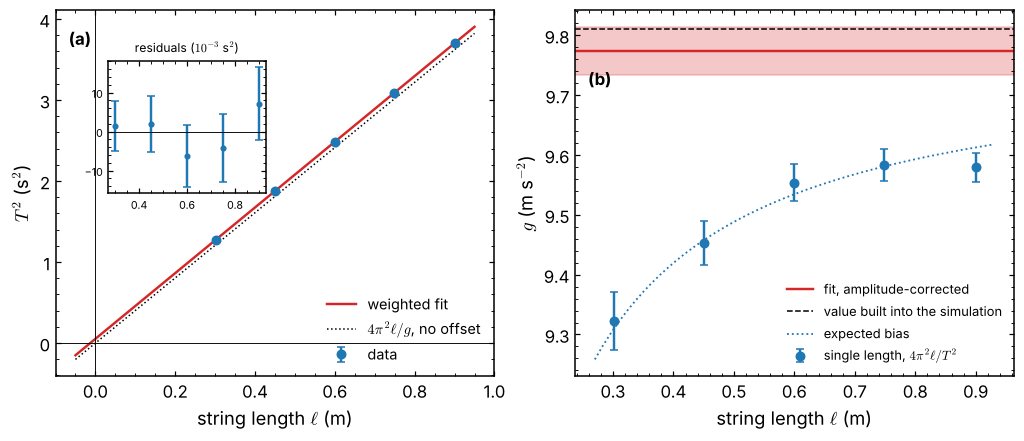

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.9))

ax = axes[0]
lg = np.linspace(-0.05, 0.95, 100)
yg, ug = fit.predict(lg)
ax.errorbar(length, T2, yerr=sigma_T2, fmt="o", color="C0", label="data")
ax.plot(lg, yg, "C3", label="weighted fit")
ax.plot(lg, 4 * np.pi**2 / 9.81 * lg, "k:", lw=1, label=r"$4\pi^2\ell/g$, no offset")
ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel(r"string length $\ell$ (m)"); ax.set_ylabel(r"$T^2$ (s$^2$)")
ax.legend(loc="lower right"); ep.panel_label(ax, "(a)")
ins = ax.inset_axes([0.12, 0.50, 0.36, 0.36])
ins.errorbar(length, fit.residuals * 1e3, yerr=sigma_T2 * 1e3, fmt="o", ms=3, color="C0")
ins.axhline(0, color="k", lw=0.6)
ins.set_title("residuals ($10^{-3}$ s$^2$)", fontsize=8); ins.tick_params(labelsize=7)

ax = axes[1]
ax.errorbar(length, g_single[:, 0], yerr=g_single[:, 1], fmt="o", color="C0",
            label="single length, $4\\pi^2\\ell/T^2$")
ax.axhspan(g_corr - u_total, g_corr + u_total, color="C3", alpha=0.25)
ax.axhline(g_corr, color="C3", label="fit, amplitude-corrected")
ax.axhline(9.810, color="k", ls="--", lw=1, label="value built into the simulation")
ll = np.linspace(0.27, 0.93, 50)
ax.plot(ll, 9.81 * ll / (ll + r_ball) / corr**2, "C0:", lw=1.2, label="expected bias")
ax.set_xlabel(r"string length $\ell$ (m)"); ax.set_ylabel("$g$ (m s$^{-2}$)")
ax.legend(loc="lower right", fontsize=8.5); ep.panel_label(ax, "(b)", y=0.84)
plt.show()

Panel (a): the fitted line misses the origin, and the intercept on the
length axis is $-\delta$. Panel (b): the single-length values (points)
climb towards the true value as the string gets longer, following the
bias expected from the two neglected effects (dotted curve), while the
fitted, corrected value (band) agrees with the value built into the
simulation.

## Step 5. Is the final uncertainty honest?

One experiment cannot answer this: a single result within one standard
uncertainty of the true value proves little. With a simulated apparatus we can repeat the
*entire* experiment and analysis many times and compare the quoted
uncertainty with the actual scatter of the final results.

In [10]:
def run_experiment(rng):
    """Simulate the experiment and return the final g and its statistical uncertainty."""
    l = np.round(length_nominal + rng.normal(0, u_len, 5), 3)
    t = np.round(n_osc * T_actual[:, None] + rng.normal(0, sigma_t, (5, n_rep)), 2)
    sp = np.sqrt(np.mean(t.std(axis=1, ddof=1)**2))
    Tm, uT = t.mean(axis=1) / n_osc, sp / np.sqrt(n_rep) / n_osc
    f = ep.linear_fit(l, Tm**2, sigma=np.sqrt((2 * Tm * uT)**2 + (4.0 * u_len)**2))
    g = 4 * np.pi**2 / f.slope * corr**2
    return g, g * f.u_slope / f.slope, f.chi2_red

res = np.array([run_experiment(rng) for _ in range(4000)])
print(f"mean of the final g over 4000 experiments : {res[:, 0].mean():.4f} m/s^2   (built in: {g_true})")
print(f"actual scatter of the final g             : {res[:, 0].std(ddof=1):.4f} m/s^2")
print(f"typical quoted statistical uncertainty    : {np.median(res[:, 1]):.4f} m/s^2")
print(f"fraction within one quoted uncertainty    : {np.mean(np.abs(res[:, 0] - g_true) < res[:, 1]):.3f}")
print(f"mean reduced chi-square of the fits       : {res[:, 2].mean():.2f}")

mean of the final g over 4000 experiments : 9.8107 m/s^2   (built in: 9.81)
actual scatter of the final g             : 0.0413 m/s^2
typical quoted statistical uncertainty    : 0.0399 m/s^2
fraction within one quoted uncertainty    : 0.665
mean reduced chi-square of the fits       : 1.08


The analysis is unbiased, the quoted uncertainty agrees with the actual
scatter to a few per cent, and the coverage is close to the expected 68 %. (The amplitude was exactly
10° in every simulated run, so only the statistical part is tested here.)

## What this example teaches

| Stage | Outcome | Comment |
|---|---|---|
| one length, textbook formula | precise but wrong | the budget covered only *random* effects |
| five lengths, same formula | values inconsistent, trend with $\ell$ | a trend is the fingerprint of a systematic error |
| straight-line fit | slope unaffected by the offset | the offset is absorbed in the intercept |
| amplitude correction | final value | common correction: its uncertainty is added at the end |
| repeated simulation | uncertainty verified | possible because the truth is known |

1. A small uncertainty is not evidence of a correct result.
2. Vary the conditions. Had only one length been used, nothing would have
   looked wrong.
3. Design the analysis so that likely systematic errors fall into
   parameters you do not care about.
4. Distinguish uncertainties that are independent from point to point
   (they go into the weights) from those common to all points (they go into
   the final budget).

## Exercises

1. Redo the analysis without the effective-variance term for the length.
   How do $u_g$ and $\chi^2_\nu$ change?
2. The stopwatch runs slow by one part in a thousand. How does this affect
   $g$? Would the fit reveal it? Would varying the length reveal it?
3. Suppose the ball's diameter had been measured with a calliper as
   $30.0 \pm 0.1$ mm and the lengths corrected accordingly. Fit a line
   through the origin, $T^2 = b(\ell + r)$, and compare the uncertainty of
   $g$ with that of the two-parameter fit. Why is it smaller?
4. Change the hidden truth in the "apparatus" cell (for example a
   different `r_ball` or amplitude) and hand the printed data table to a
   colleague to analyse.

---

**Previous:** [19. Numerical error](../part4_advanced/19_numerical_error.ipynb) &nbsp;·&nbsp; **Next:** [21. Chemical engineering: viscosity from a falling sphere](21_falling_sphere_viscosity.ipynb)